In [1]:
# ═══════════════════════════════════════════════════════════════════════
# NBA PLAYOFF SUCCESS PREDICTOR — CLEAN VERSION
# ═══════════════════════════════════════════════════════════════════════
# Predicts how far NBA teams go in playoffs (0-5 scale) from regular season stats
# 0 = missed playoffs, 1 = first round exit, ..., 5 = champion

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
import statsmodels.api as sm
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

# Data lives in data/ at the repo root (see data/README.md). This notebook runs from notebooks/.
DATA_DIR = Path("..") / "data"

# Load core files
print("Loading data files...")
team_stats = pd.read_csv(DATA_DIR / "TeamStatistics.csv")
games      = pd.read_csv(DATA_DIR / "Games.csv")
player_stats = pd.read_csv(DATA_DIR / "PlayerStatistics.csv")

print(f"✓ TeamStatistics: {team_stats.shape}")
print(f"✓ Games: {games.shape}")
print(f"✓ PlayerStatistics: {player_stats.shape}")

# An NBA season runs October to June. NBA game IDs encode the season: 22401234 is a 2024-25 regular-season game. Each season is
# labeled by the year it ends, so 2024-25 is 2025. This also keeps the 2020 bubble playoffs,
# which ran into October 2020, in the 2019-20 season.
def season_from_game_id(game_id):
    yy = game_id // 100000 % 100
    return np.where(yy >= 46, 1900, 2000) + yy + 1

# The first digit of a game ID is the game type: 2 is a regular-season game that counts in the standings.
# This includes NBA Cup group games and leaves out the NBA Cup final (6), play-in games (5), and playoffs (4).
def is_regular_season(game_id):
    return game_id // 10_000_000 == 2

Loading data files...


✓ TeamStatistics: (146048, 48)
✓ Games: (73023, 22)
✓ PlayerStatistics: (1663149, 35)


In [2]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 2: BUILD TARGET VARIABLE (Playoff Rounds 0-5)
# ═══════════════════════════════════════════════════════════════════════

print("Building playoff target variable...")

# Clean playoff rounds
playoff_games = games[games['gameType'] == 'Playoffs'].copy()
playoff_games['season'] = season_from_game_id(playoff_games['gameId'])
playoff_games = playoff_games[playoff_games['season'] >= 1997]

# Standardize round labels
label_map = {
    'West - First Round': 'First Round', 'East - First Round': 'First Round',
    'West First Round': 'First Round', 'East First Round': 'First Round',
    'East - Conf. Semifinals': 'Conf. Semifinals', 'West - Conf. Semifinals': 'Conf. Semifinals',
    'East Conf. Semifinals': 'Conf. Semifinals', 'West Conf. Semifinals': 'Conf. Semifinals',
    'East - Conf. Finals': 'Conf. Finals', 'West - Conf. Finals': 'Conf. Finals',
    'East Conf. Finals': 'Conf. Finals', 'West Conf. Finals': 'Conf. Finals',
    'NBA Finals': 'NBA Finals',
}
playoff_games['roundNum'] = playoff_games['gameLabel'].map(label_map).map(
    {'First Round': 1, 'Conf. Semifinals': 2, 'Conf. Finals': 3, 'NBA Finals': 4}
)
playoff_games = playoff_games.dropna(subset=['roundNum'])

# Identify champions
champions = (playoff_games[playoff_games['roundNum'] == 4]
             .sort_values('seriesGameNumber').groupby('season').last()
             .reset_index()[['season', 'winner']])

# Max round per team
team_rounds = pd.concat([
    playoff_games[['season','hometeamId','roundNum']].rename(columns={'hometeamId':'teamId'}),
    playoff_games[['season','awayteamId','roundNum']].rename(columns={'awayteamId':'teamId'})
]).groupby(['season','teamId'])['roundNum'].max().reset_index()
team_rounds.columns = ['season', 'teamId', 'playoff_rounds']

# Upgrade champions to 5
team_rounds = team_rounds.merge(champions, on='season', how='left')
team_rounds.loc[team_rounds['teamId'] == team_rounds['winner'], 'playoff_rounds'] = 5

# Add non-playoff teams (0s)
all_teams = pd.concat([
    games[is_regular_season(games['gameId'])][['hometeamId','gameId']].rename(columns={'hometeamId':'teamId'}),
    games[is_regular_season(games['gameId'])][['awayteamId','gameId']].rename(columns={'awayteamId':'teamId'})
])
all_teams['season'] = season_from_game_id(all_teams['gameId'])
all_teams = all_teams[(all_teams['season'] >= 1997) & (all_teams['season'] <= 2025)][['teamId','season']].drop_duplicates()

full_target = all_teams.merge(team_rounds[['season','teamId','playoff_rounds']], on=['teamId','season'], how='left')
full_target['playoff_rounds'] = full_target['playoff_rounds'].fillna(0).astype(int)

print(f"✓ Built: {len(full_target)} team/seasons, 1997-2025")
print(full_target['playoff_rounds'].value_counts().sort_index())

Building playoff target variable...
✓ Built: 862 team/seasons, 1997-2025
playoff_rounds
0    398
1    232
2    116
3     58
4     29
5     29
Name: count, dtype: int64


In [3]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 3: TEAM FEATURES FROM REGULAR SEASON
# ═══════════════════════════════════════════════════════════════════════

print("Building team features...")

# Filter to regular season 1997-2025
team_stats['season'] = season_from_game_id(team_stats['gameId'])
regular_season_gameIds = set(games.loc[is_regular_season(games['gameId']), 'gameId'])
rs_box = team_stats[(team_stats['season'] >= 1997) & 
                     (team_stats['season'] <= 2025) &
                     (team_stats['gameId'].isin(regular_season_gameIds))].copy()

# Aggregate to season totals per team
agg = rs_box.groupby(['teamId','season']).agg(
    games = ('win', 'count'),
    wins = ('win', 'sum'),
    pts = ('teamScore', 'sum'),
    opp_pts = ('opponentScore', 'sum'),
    fga = ('fieldGoalsAttempted', 'sum'),
    fgm = ('fieldGoalsMade', 'sum'),
    tpa = ('threePointersAttempted', 'sum'),
    tpm = ('threePointersMade', 'sum'),
    fta = ('freeThrowsAttempted', 'sum'),
    ftm = ('freeThrowsMade', 'sum'),
    oreb = ('reboundsOffensive', 'sum'),
    dreb = ('reboundsDefensive', 'sum'),
    tov = ('turnovers', 'sum'),
    ast = ('assists', 'sum'),
    blk = ('blocks', 'sum'),
    stl = ('steals', 'sum'),
).reset_index()

# Calculate advanced stats
agg['poss'] = agg['fga'] - agg['oreb'] + agg['tov'] + 0.44 * agg['fta']
agg['win_pct'] = agg['wins'] / agg['games']
agg['net_rating'] = (agg['pts'] - agg['opp_pts']) / agg['poss'] * 100
agg['off_rating'] = agg['pts'] / agg['poss'] * 100
agg['def_rating'] = agg['opp_pts'] / agg['poss'] * 100
agg['ts_pct'] = agg['pts'] / (2 * (agg['fga'] + 0.44 * agg['fta']))
agg['efg_pct'] = (agg['fgm'] + 0.5 * agg['tpm']) / agg['fga']
agg['tov_pct'] = agg['tov'] / (agg['fga'] + 0.44 * agg['fta'] + agg['tov'])
agg['3p_pct'] = agg['tpm'] / agg['tpa']
agg['ft_pct'] = agg['ftm'] / agg['fta']
agg['oreb_pct'] = agg['oreb'] / (agg['oreb'] + agg['dreb'])
agg['ast_pg'] = agg['ast'] / agg['games']
agg['blk_pg'] = agg['blk'] / agg['games']
agg['stl_pg'] = agg['stl'] / agg['games']
agg['tov_pg'] = agg['tov'] / agg['games']

team_features = agg[['teamId','season','win_pct','net_rating','off_rating','def_rating',
                      'ts_pct','efg_pct','tov_pct','3p_pct','ft_pct','oreb_pct',
                      'ast_pg','blk_pg','stl_pg','tov_pg']].dropna()

print(f"✓ Built: {len(team_features)} team/seasons with {len(team_features.columns)-2} features")
print(f"\nSample (2025 top 3 by net_rating):")
print(team_features[team_features['season']==2025].nlargest(3,'net_rating')[
    ['teamId','net_rating','win_pct','ts_pct']].to_string(index=False))

Building team features...
✓ Built: 862 team/seasons with 14 features

Sample (2025 top 3 by net_rating):
    teamId  net_rating  win_pct   ts_pct
1610612760   12.606528 0.829268 0.592693
1610612739    9.370971 0.780488 0.607257
1610612738    9.256964 0.743902 0.590662


In [4]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 4: MERGE DATA & BUILD MODELS
# ═══════════════════════════════════════════════════════════════════════

print("Merging features with target...")

# Merge team features + target
model_df = team_features.merge(full_target, on=['teamId','season'], how='inner')

# Add temporal weights (recent seasons matter slightly more)
LAMBDA = 0.01  # Tuned — minimal decay because older seasons are still informative
CURRENT_YEAR = 2025
model_df['years_ago'] = CURRENT_YEAR - model_df['season']
model_df['weight'] = np.exp(-LAMBDA * model_df['years_ago'])

print(f"✓ Model dataset: {len(model_df)} team/seasons, {len(team_features.columns)-2} features")
print(f"\nTarget distribution:")
print(model_df['playoff_rounds'].value_counts().sort_index())

# ── Define features ────────────────────────────────────────────────────
FEATURES = ['win_pct', 'net_rating', 'off_rating', 'def_rating',
            'ts_pct', 'efg_pct', 'tov_pct', '3p_pct', 'ft_pct', 'oreb_pct',
            'ast_pg', 'blk_pg', 'stl_pg', 'tov_pg']

X = model_df[FEATURES].values
y = model_df['playoff_rounds'].values
w = model_df['weight'].values

# The WLS fit below is in-sample, with no train/test split, so scaling on all rows is fine there.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ── Cross-validation helper ────────────────────────────────────────────
# Every CV loop holds out whole seasons (GroupKFold by season), so a team's season is never split
# between training and testing, and teams from the same season are always tested together.
# The scaler is fit on each fold's training rows only, so the test season never informs the scaling.
def make_xgb():
    return XGBRegressor(max_depth=2, n_estimators=500, learning_rate=0.01,
                        reg_alpha=1.0, reg_lambda=5.0, subsample=0.8,
                        colsample_bytree=0.8, random_state=42)

def cv_r2(make_model, X, y, w, groups, n_splits=5):
    scores = []
    for train_idx, test_idx in GroupKFold(n_splits=n_splits).split(X, y, groups):
        fold_scaler = StandardScaler().fit(X[train_idx])
        model = make_model()
        model.fit(fold_scaler.transform(X[train_idx]), y[train_idx], sample_weight=w[train_idx])
        y_pred = model.predict(fold_scaler.transform(X[test_idx]))
        ss_res = np.sum((y[test_idx] - y_pred) ** 2)
        ss_tot = np.sum((y[test_idx] - np.mean(y[test_idx])) ** 2)
        scores.append(1 - ss_res / ss_tot)
    return scores

# ── Model 1: Baseline OLS ──────────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 1: Weighted OLS (Baseline)")
print("="*70)

X_const = sm.add_constant(X_scaled)
ols_model = sm.WLS(y, X_const, weights=w).fit()
print(f"R²: {ols_model.rsquared:.3f}")

# ── Model 2: XGBoost (Tuned) ───────────────────────────────────────────
print("\n" + "="*70)
print("MODEL 2: XGBoost (Cross-Validated)")
print("="*70)

groups = model_df['season'].values
r2_scores = cv_r2(make_xgb, X, y, w, groups)

print(f"CV R²: {np.mean(r2_scores):.3f} ± {np.std(r2_scores):.3f}")
print(f"Folds: {[round(s,3) for s in r2_scores]}")

Merging features with target...
✓ Model dataset: 862 team/seasons, 14 features

Target distribution:
playoff_rounds
0    398
1    232
2    116
3     58
4     29
5     29
Name: count, dtype: int64

MODEL 1: Weighted OLS (Baseline)
R²: 0.588

MODEL 2: XGBoost (Cross-Validated)


CV R²: 0.677 ± 0.025
Folds: [np.float64(0.68), np.float64(0.707), np.float64(0.632), np.float64(0.691), np.float64(0.674)]


In [5]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 5: WHAT ACTUALLY MATTERS?
# ═══════════════════════════════════════════════════════════════════════
# Test: How much does complexity buy us vs. the simplest possible predictor?

print("Testing individual feature predictive power...\n")

single_feature_results = []

for feat in FEATURES:
    X_single = model_df[[feat]].values
    scores = cv_r2(LinearRegression, X_single, y, w, groups)
    single_feature_results.append({
        'feature': feat,
        'r2': np.mean(scores)
    })

results_df = pd.DataFrame(single_feature_results).sort_values('r2', ascending=False)

win_r2 = results_df.set_index('feature').loc['win_pct', 'r2']

print("Top 5 individual features:")
print(results_df.head(5).to_string(index=False))

print("\n" + "="*70)
print("THE FINDING")
print("="*70)
print(f"Win % alone:              {win_r2:.3f}")
print(f"Full XGBoost (14 features): {np.mean(r2_scores):.3f}")
print(f"Improvement from complexity: {np.mean(r2_scores) - win_r2:.3f}")
print(f"\nWin % captures {win_r2 / np.mean(r2_scores) * 100:.1f}% of what's predictable")

Testing individual feature predictive power...

Top 5 individual features:
   feature       r2
   win_pct 0.581003
net_rating 0.545492
off_rating 0.131393
def_rating 0.120479
    ts_pct 0.118806

THE FINDING
Win % alone:              0.581
Full XGBoost (14 features): 0.677
Improvement from complexity: 0.096

Win % captures 85.9% of what's predictable


In [6]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 6: SEEDING & MOMENTUM FEATURES
# ═══════════════════════════════════════════════════════════════════════

print("Adding playoff seeding (by conference)...")

# Map teams to conferences (current alignment - limitation for historical shifts)
EAST = {1610612738, 1610612751, 1610612752, 1610612755, 1610612754, 1610612756,
        1610612765, 1610612741, 1610612739, 1610612766, 1610612748, 1610612749,
        1610612761, 1610612764, 1610612737}  # 15 Eastern teams
# Everyone else is West

model_df['conference'] = model_df['teamId'].apply(lambda x: 'East' if x in EAST else 'West')
model_df['playoff_seed'] = 0

for season in model_df['season'].unique():
    for conf in ['East', 'West']:
        conf_teams = model_df[(model_df['season'] == season) & 
                               (model_df['conference'] == conf)].copy()
        top8 = conf_teams.nlargest(8, 'win_pct')
        
        for seed, (idx, row) in enumerate(top8.iterrows(), start=1):
            model_df.loc[idx, 'playoff_seed'] = seed

print(f"✓ Conference-based seeding added")

# ── Late-season form ───────────────────────────────────────────────────
print("Calculating late-season form...")

late_form = []
for (teamId, season), grp in rs_box.groupby(['teamId','season']):
    grp = grp.sort_values('gameDateTimeEst')
    last20 = grp.tail(20)
    
    if len(last20) < 20:
        continue
    
    pts = last20['teamScore'].sum()
    opp = last20['opponentScore'].sum()
    poss = (last20['fieldGoalsAttempted'].sum() - last20['reboundsOffensive'].sum() 
            + last20['turnovers'].sum() + 0.44 * last20['freeThrowsAttempted'].sum())
    
    late_form.append({
        'teamId': teamId,
        'season': season,
        'late_net_rating': (pts - opp) / poss * 100
    })

late_df = pd.DataFrame(late_form)
model_df = model_df.merge(late_df, on=['teamId','season'], how='left')
model_df['late_form'] = model_df['late_net_rating'] - model_df['net_rating']
model_df = model_df.dropna(subset=['late_form'])

print(f"✓ Late-season form added ({len(model_df)} rows)")

# ── Rerun model ────────────────────────────────────────────────────────
FEATURES_V2 = FEATURES + ['playoff_seed', 'late_form']
X_v2 = model_df[FEATURES_V2].values
y_v2 = model_df['playoff_rounds'].values
w_v2 = model_df['weight'].values

groups_v2 = model_df['season'].values
r2_scores_v2 = cv_r2(make_xgb, X_v2, y_v2, w_v2, groups_v2)

print("\n" + "="*70)
print(f"Baseline:               {np.mean(r2_scores):.3f}")
print(f"+ Seeding + Late Form:  {np.mean(r2_scores_v2):.3f}")
print(f"Improvement:            {np.mean(r2_scores_v2) - np.mean(r2_scores):.3f}")

Adding playoff seeding (by conference)...


✓ Conference-based seeding added
Calculating late-season form...


✓ Late-season form added (862 rows)



Baseline:               0.677
+ Seeding + Late Form:  0.719
Improvement:            0.042


In [7]:
team_lookup = {
    1610612737: "Atlanta Hawks",
    1610612738: "Boston Celtics",
    1610612739: "Cleveland Cavaliers",
    1610612740: "New Orleans Pelicans",
    1610612741: "Chicago Bulls",
    1610612742: "Dallas Mavericks",
    1610612743: "Denver Nuggets",
    1610612744: "Golden State Warriors",
    1610612745: "Houston Rockets",
    1610612746: "Los Angeles Clippers",
    1610612747: "Los Angeles Lakers",
    1610612748: "Miami Heat",
    1610612749: "Milwaukee Bucks",
    1610612750: "Minnesota Timberwolves",
    1610612751: "Brooklyn Nets",
    1610612752: "New York Knicks",
    1610612753: "Orlando Magic",
    1610612754: "Indiana Pacers",
    1610612755: "Philadelphia 76ers",
    1610612756: "Phoenix Suns",
    1610612757: "Portland Trail Blazers",
    1610612758: "Sacramento Kings",
    1610612759: "San Antonio Spurs",
    1610612760: "Oklahoma City Thunder",
    1610612761: "Toronto Raptors",
    1610612762: "Utah Jazz",
    1610612763: "Memphis Grizzlies",
    1610612764: "Washington Wizards",
    1610612765: "Detroit Pistons",
    1610612766: "Charlotte Hornets"
}

In [8]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 7: REAL-WORLD VALIDATION (2025 HOLDOUT)
# ═══════════════════════════════════════════════════════════════════════

print("Testing on 2025 season (never seen by model)...\n")

train_mask = model_df['season'] <= 2024
test_mask = model_df['season'] == 2025

# Fit the scaler on the training seasons only, then apply it to 2025.
holdout_scaler = StandardScaler().fit(X_v2[train_mask])
X_train = holdout_scaler.transform(X_v2[train_mask])
X_test = holdout_scaler.transform(X_v2[test_mask])
y_train = y_v2[train_mask]
y_test = y_v2[test_mask]
w_train = w_v2[train_mask]

final_model = make_xgb()
final_model.fit(X_train, y_train, sample_weight=w_train)
y_pred = final_model.predict(X_test)

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)
r2_2025 = 1 - ss_res / ss_tot

# Build constrained predictions (enforce playoff structure)
results_2025 = model_df[test_mask][['teamId','season','playoff_rounds']].copy()
results_2025['predicted'] = y_pred
results_2025 = results_2025.sort_values('predicted', ascending=False).reset_index(drop=True)

# Assign slots: 14 miss playoffs, 8 R1, 4 R2, 2 R3, 1 R4, 1 champ
slots = {5:1, 4:1, 3:2, 2:4, 1:8, 0:14}
constrained = []
for rounds, count in sorted(slots.items(), reverse=True):
    constrained.extend([rounds] * count)
results_2025['constrained_pred'] = constrained
results_2025['name'] = results_2025['teamId'].map(team_lookup)

exact = (results_2025['constrained_pred'] == results_2025['playoff_rounds']).sum()
within_one = (abs(results_2025['constrained_pred'] - results_2025['playoff_rounds']) <= 1).sum()

print(f"2025 Holdout R²: {r2_2025:.3f}")
print(f"Exact matches: {exact}/30 ({exact/30*100:.0f}%)")
print(f"Within 1 round: {within_one}/30 ({within_one/30*100:.0f}%)")

print(f"\nTop 10 predicted teams:")
print(results_2025.head(10)[['name','playoff_rounds','constrained_pred']].to_string(index=False))

Testing on 2025 season (never seen by model)...

2025 Holdout R²: 0.559
Exact matches: 16/30 (53%)
Within 1 round: 26/30 (87%)

Top 10 predicted teams:
                 name  playoff_rounds  constrained_pred
  Cleveland Cavaliers               2                 5
Oklahoma City Thunder               5                 4
       Boston Celtics               2                 3
      Houston Rockets               1                 3
       Denver Nuggets               2                 2
      New York Knicks               3                 2
   Los Angeles Lakers               1                 2
 Los Angeles Clippers               1                 2
       Indiana Pacers               4                 1
      Milwaukee Bucks               1                 1


In [9]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 8: ADD INJURY DATA
# ═══════════════════════════════════════════════════════════════════════
# IMPORTANT:
# This section does NOT merge injuries directly into model_df.
# It creates model_df_v3, so the original modeling table stays clean.

print("Loading combined injury data...")
injury_df = pd.read_csv(DATA_DIR / "combined_injuries_1997-2025.csv")

injury_df['teamId'] = pd.to_numeric(injury_df['teamId'], errors='coerce')
injury_df['Date'] = pd.to_datetime(injury_df['Date'], errors='coerce')
# The file's season column is the calendar year. October to December belongs to the next season,
# except the 2020 bubble playoffs, which ran until October 11, 2020.
injury_df['season'] = injury_df['Date'].dt.year + (injury_df['Date'].dt.month >= 10).astype(int)
injury_df.loc[(injury_df['Date'] >= '2020-10-01') & (injury_df['Date'] <= '2020-10-11'), 'season'] = 2020

# Keep only valid team-season-date rows
injury_df = injury_df.dropna(subset=['teamId', 'season', 'Date'])

# Keep only actual injury/removal events.
# Relinquished = the player was removed from active status / listed as injured.
# Acquired usually represents a return/activation, so counting every row would inflate injuries.
injury_df = injury_df[
    injury_df['Relinquished'].notna() &
    (injury_df['Relinquished'].astype(str).str.strip() != "")
].copy()

# Remove exact duplicate injury records
# Only use columns that actually exist, so this stays safe if the file changes slightly.
dedupe_cols = [col for col in ['Date', 'teamId', 'season', 'Relinquished', 'Notes'] if col in injury_df.columns]
injury_df = injury_df.drop_duplicates(subset=dedupe_cols)

# Aggregate true regular-season injury events to team-season counts
injury_counts = (
    injury_df
    .groupby(['teamId', 'season'])
    .size()
    .reset_index(name='reg_season_injuries')
)

print(f"Injury counts aggregated: {len(injury_counts)} team/seasons")

# Safety check: injury_counts must have exactly one row per team-season
duplicate_keys = injury_counts[injury_counts.duplicated(['teamId', 'season'], keep=False)]
print(f"Duplicate team-season rows in injury_counts: {len(duplicate_keys)}")

if len(duplicate_keys) > 0:
    raise ValueError("injury_counts has duplicate team-season rows. Fix before merging.")

# Create a clean V3 modeling dataframe.
# Do not mutate model_df directly; keep it as the clean base/V2 table.
model_df_v3 = model_df.copy()

# If this cell is rerun, remove old injury columns from the V3 copy only.
model_df_v3 = model_df_v3.drop(
    columns=[col for col in model_df_v3.columns if 'injur' in col.lower()],
    errors='ignore'
)

# Merge into the V3 copy
before_merge = len(model_df_v3)
model_df_v3 = model_df_v3.merge(
    injury_counts,
    on=['teamId', 'season'],
    how='left',
    validate='many_to_one'
)

model_df_v3['reg_season_injuries'] = (
    model_df_v3['reg_season_injuries']
    .fillna(0)
    .astype(int)
)

print(f"✓ Injuries merged into model_df_v3: {len(model_df_v3)} rows (was {before_merge})")
print(f"Teams with injury data: {(model_df_v3['reg_season_injuries'] > 0).sum()}")

# Rebuild model with injuries
FEATURES_V3 = FEATURES_V2 + ['reg_season_injuries']
X_v3 = model_df_v3[FEATURES_V3].values
y_v3 = model_df_v3['playoff_rounds'].values
w_v3 = model_df_v3['weight'].values

groups_v3 = model_df_v3['season'].values
r2_scores_v3 = cv_r2(make_xgb, X_v3, y_v3, w_v3, groups_v3)

print("\n" + "="*70)
print("MODEL PROGRESSION")
print("="*70)
print(f"Win % alone:                     {win_r2:.3f}")
print(f"Full team stats (14 features):   {np.mean(r2_scores):.3f}")
print(f"+ Seeding + Late Form (16):      {np.mean(r2_scores_v2):.3f}")
print(f"+ Injuries (17 features total):  {np.mean(r2_scores_v3):.3f}")
print(f"\nInjuries added: {np.mean(r2_scores_v3) - np.mean(r2_scores_v2):+.3f}")



Loading combined injury data...


Injury counts aggregated: 851 team/seasons
Duplicate team-season rows in injury_counts: 0
✓ Injuries merged into model_df_v3: 862 rows (was 862)
Teams with injury data: 849



MODEL PROGRESSION
Win % alone:                     0.581
Full team stats (14 features):   0.677
+ Seeding + Late Form (16):      0.719
+ Injuries (17 features total):  0.720

Injuries added: +0.001


In [10]:
from scipy.stats import pearsonr, spearmanr

combined = pd.read_csv(DATA_DIR / "combined_injuries_1997-2025.csv")
injury_data = pd.read_csv(DATA_DIR / "injury_data.csv")

injuries = pd.concat([combined, injury_data], ignore_index=True)

injuries["Date"] = pd.to_datetime(injuries["Date"])

team_name_fix = {
    "Blazers": "Trail Blazers"
}

injuries["Team"] = injuries["Team"].replace(team_name_fix)

dedupe_cols = ["Date", "Team", "Acquired", "Relinquished", "Notes"]
injuries = injuries.drop_duplicates(subset=dedupe_cols)

injuries = injuries[
    injuries["Relinquished"].notna() &
    (injuries["Relinquished"].astype(str).str.strip() != "")
].copy()

injuries["season"] = np.where(
    injuries["Date"].dt.month >= 10,
    injuries["Date"].dt.year + 1,
    injuries["Date"].dt.year
)

injuries = injuries[injuries["season"].between(2017, 2024)].copy()

In [11]:
# Actual NBA playoff start dates by season-ending year
playoff_start_dates = {
    2017: "2017-04-15",
    2018: "2018-04-14",
    2019: "2019-04-13",
    2020: "2020-08-17",  # bubble playoffs
    2021: "2021-05-22",  # delayed COVID season
    2022: "2022-04-16",
    2023: "2023-04-15",
    2024: "2024-04-20"
}

playoff_start_dates = {
    season: pd.to_datetime(date)
    for season, date in playoff_start_dates.items()
}

injuries["playoff_start"] = injuries["season"].map(playoff_start_dates)

injuries["season_type"] = np.where(
    injuries["Date"] >= injuries["playoff_start"],
    "Playoffs",
    "Regular Season"
)

season_end_dates = {
    2017: "2017-06-12",
    2018: "2018-06-08",
    2019: "2019-06-13",
    2020: "2020-10-11",
    2021: "2021-07-20",
    2022: "2022-06-16",
    2023: "2023-06-12",
    2024: "2024-06-17"
}

season_end_dates = {
    season: pd.to_datetime(date)
    for season, date in season_end_dates.items()
}

injuries["season_end"] = injuries["season"].map(season_end_dates)

injuries = injuries[injuries["Date"] <= injuries["season_end"]].copy()

In [12]:
team_season_injuries = (
    injuries
    .groupby(["season", "Team", "season_type"])
    .size()
    .reset_index(name="injury_count")
)

injury_pivot = (
    team_season_injuries
    .pivot_table(
        index=["season", "Team"],
        columns="season_type",
        values="injury_count",
        fill_value=0
    )
    .reset_index()
)

if "Regular Season" not in injury_pivot.columns:
    injury_pivot["Regular Season"] = 0

if "Playoffs" not in injury_pivot.columns:
    injury_pivot["Playoffs"] = 0

injury_pivot = injury_pivot.rename(columns={
    "Regular Season": "regular_season_injuries",
    "Playoffs": "playoff_injuries"
})

injury_pivot.head()

season_type,season,Team,playoff_injuries,regular_season_injuries
0,2017,76ers,0.0,7.0
1,2017,Bucks,2.0,27.0
2,2017,Bulls,4.0,42.0
3,2017,Cavaliers,2.0,26.0
4,2017,Celtics,4.0,40.0


In [13]:
x = injury_pivot["regular_season_injuries"]
y = injury_pivot["playoff_injuries"]

pearson_corr, pearson_p = pearsonr(x, y)
spearman_corr, spearman_p = spearmanr(x, y)

print(f"Pearson correlation:  {pearson_corr:.3f}")
print(f"Pearson p-value:      {pearson_p:.4f}")

print(f"Spearman correlation: {spearman_corr:.3f}")
print(f"Spearman p-value:     {spearman_p:.4f}")

Pearson correlation:  0.219
Pearson p-value:      0.0007
Spearman correlation: 0.187
Spearman p-value:     0.0036


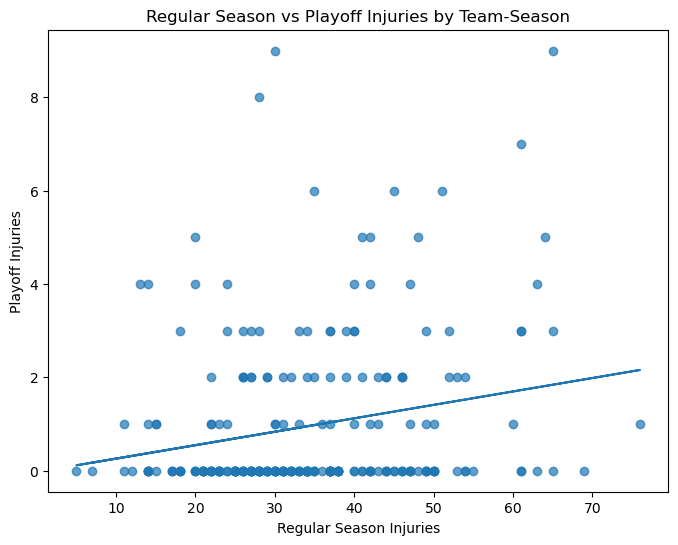

In [14]:
plt.figure(figsize=(8, 6))

plt.scatter(
    injury_pivot["regular_season_injuries"],
    injury_pivot["playoff_injuries"],
    alpha=0.7
)

plt.xlabel("Regular Season Injuries")
plt.ylabel("Playoff Injuries")
plt.title("Regular Season vs Playoff Injuries by Team-Season")

# Add trendline
m, b = np.polyfit(
    injury_pivot["regular_season_injuries"],
    injury_pivot["playoff_injuries"],
    1
)

plt.plot(
    injury_pivot["regular_season_injuries"],
    m * injury_pivot["regular_season_injuries"] + b
)

FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)
plt.savefig(FIG_DIR / "exhibit_6_injuries.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
injury_pivot.sort_values(
    by="playoff_injuries",
    ascending=False
).head(20)

season_type,season,Team,playoff_injuries,regular_season_injuries
121,2021,Bucks,9.0,30.0
23,2017,Spurs,9.0,65.0
10,2017,Jazz,8.0,28.0
154,2022,Celtics,7.0,61.0
28,2017,Warriors,6.0,51.0
22,2017,Rockets,6.0,35.0
150,2022,76ers,6.0,45.0
51,2018,Raptors,5.0,48.0
158,2022,Heat,5.0,64.0
21,2017,Raptors,5.0,20.0


In [16]:
# Compare XGBoost vs simple Linear Regression
print("Testing Linear Regression with all 17 features...\n")

lr_scores = cv_r2(LinearRegression, X_v3, y_v3, w_v3, groups_v3)

print("="*70)
print("SIMPLE vs COMPLEX")
print("="*70)
print(f"Linear Regression (17 features): {np.mean(lr_scores):.3f} ± {np.std(lr_scores):.3f}")
print(f"XGBoost (17 features):           {np.mean(r2_scores_v3):.3f} ± {np.std(r2_scores_v3):.3f}")
print(f"\nGain from complexity:            {np.mean(r2_scores_v3) - np.mean(lr_scores):+.3f}")

Testing Linear Regression with all 17 features...

SIMPLE vs COMPLEX
Linear Regression (17 features): 0.589 ± 0.037
XGBoost (17 features):           0.720 ± 0.019

Gain from complexity:            +0.131


In [17]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 9: REGRESSION COEFFICIENTS (WEIGHTED OLS)
# ═══════════════════════════════════════════════════════════════════════
# Standardized coefficients: each one is the change in playoff rounds for a one-standard-deviation
# change in that feature. In-sample fits on all 1997-2025 team-seasons, same weights as the models above.

def wls_summary(features, label):
    Xs = StandardScaler().fit_transform(model_df_v3[features].values)
    fit = sm.WLS(model_df_v3['playoff_rounds'].values, sm.add_constant(Xs),
                 weights=model_df_v3['weight'].values).fit()
    table = pd.DataFrame({'coef': fit.params[1:], 'p_value': fit.pvalues[1:]}, index=features)
    print("=" * 70)
    print(f"{label}: R² = {fit.rsquared:.3f}, adjusted R² = {fit.rsquared_adj:.3f}, n = {int(fit.nobs)}")
    print("=" * 70)
    print(table.round(3).to_string())
    print()
    return fit

wls_m1 = wls_summary(['win_pct'], "Model 1 (win % alone)")
wls_m2 = wls_summary(FEATURES, "Model 2 (14 team features)")
wls_m3 = wls_summary(FEATURES_V3, "Model 3 (17 features)")
print("Note: net_rating equals off_rating minus def_rating, so those three coefficients share one signal.")


Model 1 (win % alone): R² = 0.579, adjusted R² = 0.578, n = 862
          coef  p_value
win_pct  0.996      0.0

Model 2 (14 team features): R² = 0.588, adjusted R² = 0.582, n = 862
             coef  p_value
win_pct     0.995    0.000
net_rating -0.087    0.623
off_rating -0.212    0.532
def_rating -0.135    0.496
ts_pct      0.163    0.750
efg_pct     0.240    0.317
tov_pct     0.097    0.659
3p_pct     -0.106    0.013
ft_pct      0.027    0.559
oreb_pct    0.051    0.767
ast_pg      0.019    0.679
blk_pg      0.042    0.180
stl_pg     -0.016    0.699
tov_pg     -0.084    0.436

Model 3 (17 features): R² = 0.595, adjusted R² = 0.588, n = 862
                      coef  p_value
win_pct              1.065    0.000
net_rating          -0.081    0.647
off_rating          -0.181    0.593
def_rating          -0.108    0.583
ts_pct               0.119    0.816
efg_pct              0.194    0.415
tov_pct              0.128    0.560
3p_pct              -0.099    0.021
ft_pct               0.0

In [18]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 10: FEATURE CORRELATIONS
# ═══════════════════════════════════════════════════════════════════════

corr = model_df[FEATURES].corr()
pairs = [('win_pct', 'net_rating'), ('ts_pct', '3p_pct'), ('net_rating', 'ts_pct'), ('net_rating', '3p_pct')]
for a, b in pairs:
    r = corr.loc[a, b]
    print(f"{a} vs {b}: r = {r:.2f} (shared variance {r**2:.0%})")
print()
print(corr.round(2).to_string())


win_pct vs net_rating: r = 0.97 (shared variance 94%)
ts_pct vs 3p_pct: r = 0.60 (shared variance 37%)
net_rating vs ts_pct: r = 0.48 (shared variance 23%)
net_rating vs 3p_pct: r = 0.48 (shared variance 23%)

            win_pct  net_rating  off_rating  def_rating  ts_pct  efg_pct  tov_pct  3p_pct  ft_pct  oreb_pct  ast_pg  blk_pg  stl_pg  tov_pg
win_pct        1.00        0.97        0.53       -0.44    0.47     0.43    -0.26    0.47    0.15     -0.24    0.28    0.22    0.13   -0.35
net_rating     0.97        1.00        0.54       -0.46    0.48     0.44    -0.27    0.48    0.16     -0.23    0.28    0.22    0.15   -0.35
off_rating     0.53        0.54        1.00        0.50    0.94     0.93    -0.66    0.57    0.47     -0.52    0.65    0.02   -0.05   -0.53
def_rating    -0.44       -0.46        0.50        1.00    0.50     0.53    -0.42    0.10    0.33     -0.31    0.41   -0.21   -0.21   -0.19
ts_pct         0.47        0.48        0.94        0.50    1.00     0.98    -0.47    0.60 

In [19]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 11: LEAVE-ONE-SEASON-OUT VALIDATION
# ═══════════════════════════════════════════════════════════════════════
# Each of the 29 seasons is held out once. The final model (16 features) is trained on the other 28
# seasons, with the scaler fit on those training seasons only, and scored on the held-out season.
# The 2025 fold trains on 1997-2024, so it is the same test as the 2025 holdout in Section 7.

loso_rows = []
for season in sorted(model_df['season'].unique()):
    train = (model_df['season'] != season).values
    test = ~train
    fold_scaler = StandardScaler().fit(X_v2[train])
    model = make_xgb()
    model.fit(fold_scaler.transform(X_v2[train]), y_v2[train], sample_weight=w_v2[train])
    y_pred = model.predict(fold_scaler.transform(X_v2[test]))
    ss_res = np.sum((y_v2[test] - y_pred) ** 2)
    ss_tot = np.sum((y_v2[test] - np.mean(y_v2[test])) ** 2)
    loso_rows.append({'season': season, 'teams': int(test.sum()), 'r2': 1 - ss_res / ss_tot})

loso_df = pd.DataFrame(loso_rows)
r2_2025_loso = loso_df.loc[loso_df['season'] == 2025, 'r2'].iloc[0]
rank_2025 = int((loso_df['r2'] < r2_2025_loso).sum()) + 1

print(f"Seasons: {len(loso_df)}")
print(f"Mean R²: {loso_df['r2'].mean():.3f} | median: {loso_df['r2'].median():.3f}")
print(f"Range: {loso_df['r2'].min():.3f} ({int(loso_df.loc[loso_df['r2'].idxmin(), 'season'])}) "
      f"to {loso_df['r2'].max():.3f} ({int(loso_df.loc[loso_df['r2'].idxmax(), 'season'])})")
print(f"Middle 50%: {loso_df['r2'].quantile(0.25):.3f} to {loso_df['r2'].quantile(0.75):.3f}")
print(f"2025 holdout: {r2_2025_loso:.3f}, rank {rank_2025} of {len(loso_df)} from the lowest "
      f"({(loso_df['r2'] < r2_2025_loso).sum()} seasons lower, {(loso_df['r2'] > r2_2025_loso).sum()} higher)")
print()
print(loso_df.round(3).to_string(index=False))


Seasons: 29
Mean R²: 0.719 | median: 0.745
Range: 0.425 (2023) to 0.887 (2017)
Middle 50%: 0.675 to 0.781
2025 holdout: 0.559, rank 2 of 29 from the lowest (1 seasons lower, 27 higher)

 season  teams    r2
   1997     29 0.843
   1998     29 0.781
   1999     29 0.622
   2000     29 0.791
   2001     29 0.728
   2002     29 0.789
   2003     29 0.772
   2004     29 0.764
   2005     30 0.773
   2006     30 0.722
   2007     30 0.568
   2008     30 0.789
   2009     30 0.780
   2010     30 0.713
   2011     30 0.675
   2012     30 0.685
   2013     30 0.732
   2014     30 0.768
   2015     30 0.808
   2016     30 0.780
   2017     30 0.887
   2018     30 0.745
   2019     30 0.838
   2020     30 0.627
   2021     30 0.606
   2022     30 0.691
   2023     30 0.425
   2024     30 0.587
   2025     30 0.559


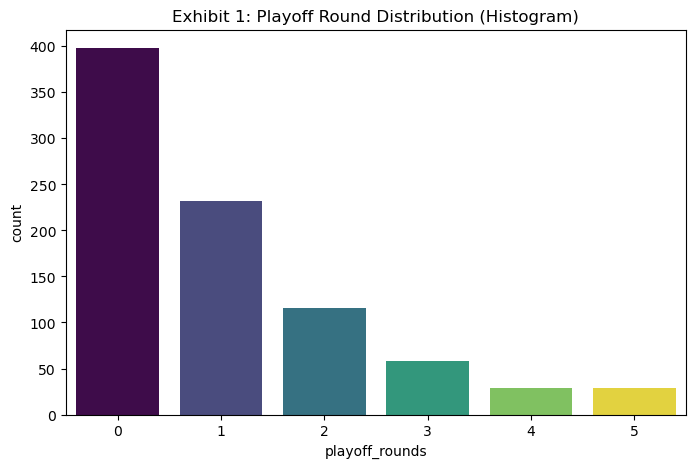

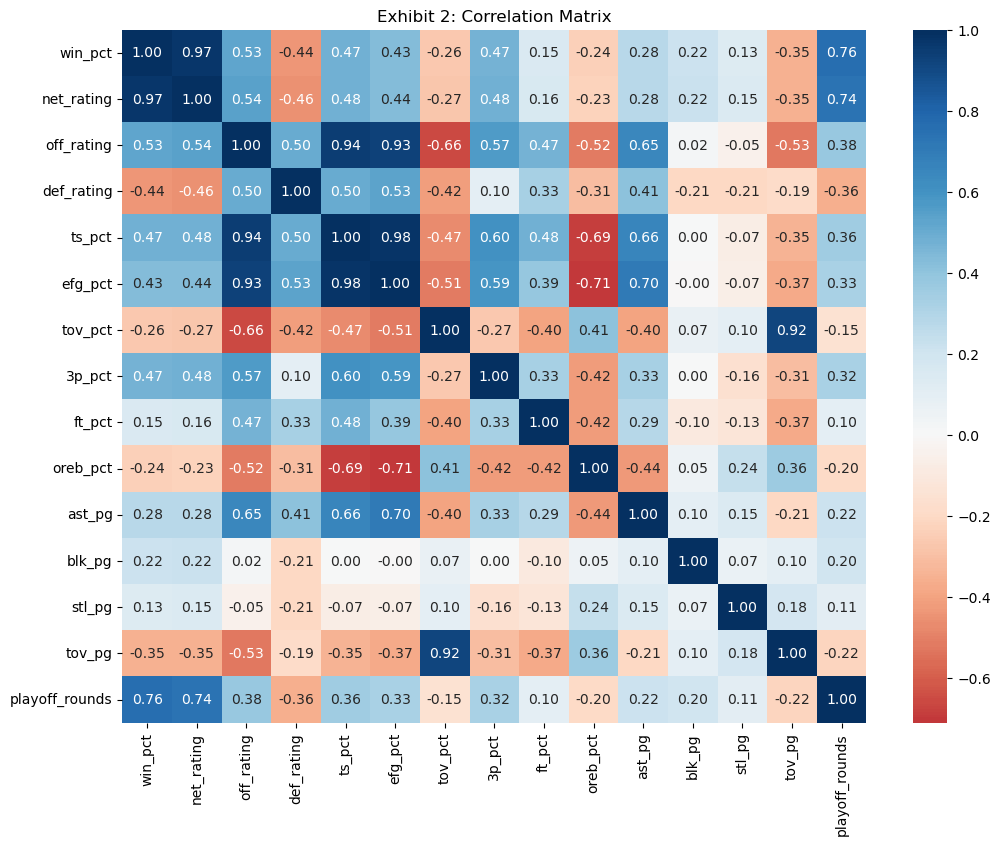

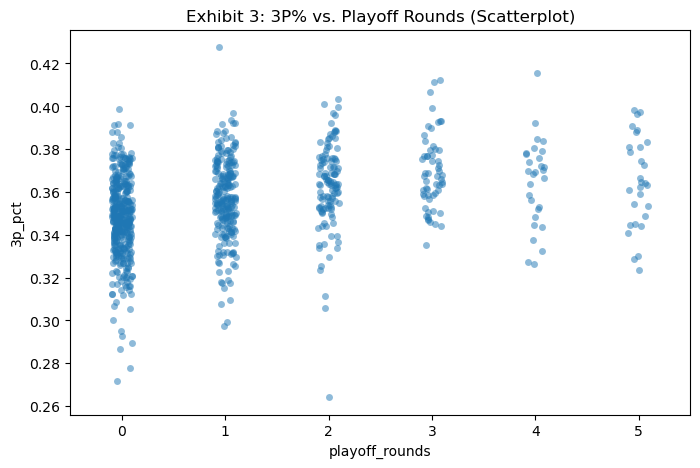

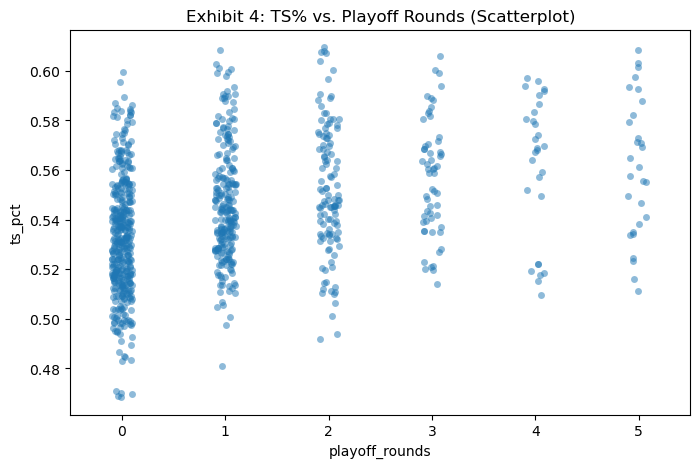

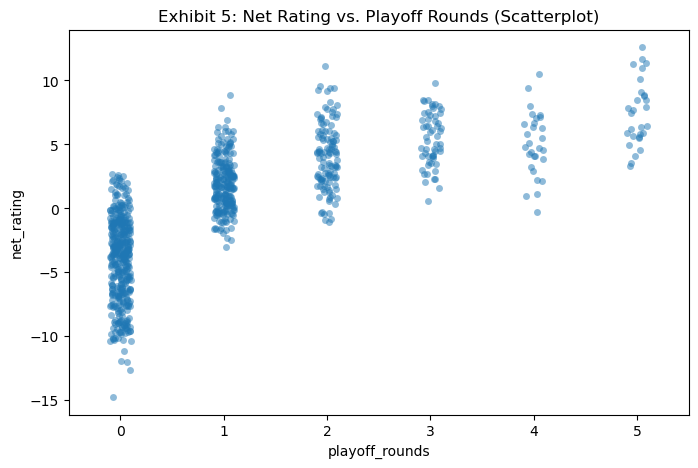

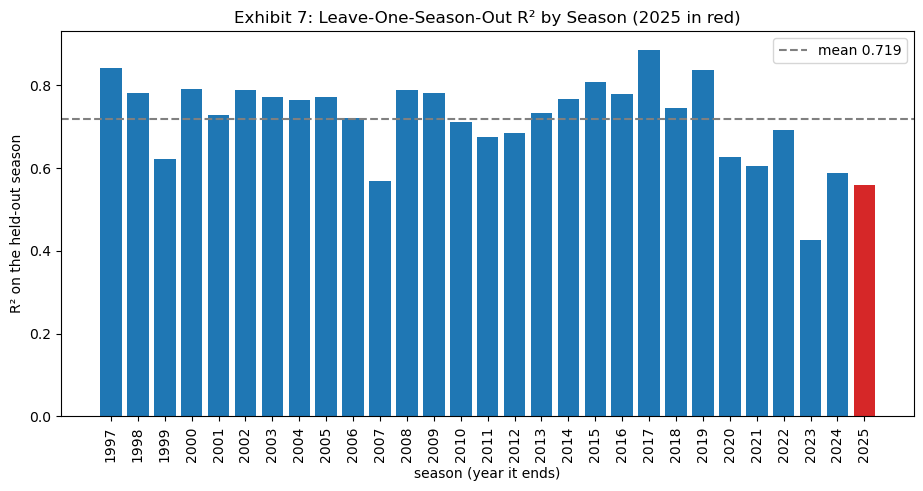

3p_pct        0.32
ts_pct        0.36
net_rating    0.74
win_pct       0.76
regular-season injuries vs playoff rounds: 0.02


In [20]:
# ═══════════════════════════════════════════════════════════════════════
# SECTION 12: EXHIBITS
# ═══════════════════════════════════════════════════════════════════════
# Every exhibit in the paper is drawn here from the same data as the models above and saved to figures/.
import seaborn as sns

FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

# Exhibit 1: playoff round distribution
fig, ax = plt.subplots(figsize=(8, 5))
counts = model_df['playoff_rounds'].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False, ax=ax)
ax.set(title="Exhibit 1: Playoff Round Distribution (Histogram)", xlabel="playoff_rounds", ylabel="count")
save(fig, "exhibit_1_distribution.png")

# Exhibit 2: correlation matrix of the 14 team features and the target
fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(model_df[FEATURES + ['playoff_rounds']].corr(), annot=True, fmt=".2f", cmap="RdBu", center=0, ax=ax)
ax.set_title("Exhibit 2: Correlation Matrix")
save(fig, "exhibit_2_correlations.png")

# Exhibits 3-5: shooting and Net Rating against playoff rounds
for num, col, label in [(3, '3p_pct', '3P%'), (4, 'ts_pct', 'TS%'), (5, 'net_rating', 'Net Rating')]:
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.stripplot(data=model_df, x='playoff_rounds', y=col, alpha=0.5, jitter=0.1, ax=ax)
    ax.set_title(f"Exhibit {num}: {label} vs. Playoff Rounds (Scatterplot)")
    save(fig, f"exhibit_{num}_{col.replace('3p', 'three_p')}.png")

# Exhibit 7: leave-one-season-out R² by season
fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#d62728' if s == 2025 else '#1f77b4' for s in loso_df['season']]
ax.bar(loso_df['season'].astype(str), loso_df['r2'], color=colors)
ax.axhline(loso_df['r2'].mean(), color='gray', linestyle='--', label=f"mean {loso_df['r2'].mean():.3f}")
ax.set(title="Exhibit 7: Leave-One-Season-Out R² by Season (2025 in red)", xlabel="season (year it ends)",
       ylabel="R² on the held-out season")
ax.tick_params(axis='x', rotation=90)
ax.legend()
save(fig, "exhibit_7_loso.png")

# Correlations with the target, for the text describing Exhibits 3-5
print(model_df[['3p_pct', 'ts_pct', 'net_rating', 'win_pct']].corrwith(model_df['playoff_rounds']).round(2).to_string())
print("regular-season injuries vs playoff rounds:",
      round(model_df_v3['reg_season_injuries'].corr(model_df_v3['playoff_rounds']), 2))
